# Creating a Decision Tree Using the CART Algorithm

## About This Project

In this project, you will create a decision tree by implementing the Classification and Regression Tree (CART) algorithm. You will work with the [Ionosphere Data Set from the UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Ionosphere), which consists of radar data from a system designed to target free electrons in the ionosphere, and a artificial "spiral" dataset. The first dataset will be used to determine if a radar return was "good" (i.e., a signal was returned) or "bad" (i.e., the signal passed straight through the ionosphere).

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter Notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

Before you get started, let's import a few packages that you will need. In addition, you will load two binary classification dataset &mdash; the spiral dataset and the [ION dataset](https://archive.ics.uci.edu/ml/datasets/Ionosphere).

In [1]:
import numpy as np
import pandas as pd
from numpy.matlib import repmat
from scipy.io import loadmat
import time

# Interactive plots
%matplotlib ipympl
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


The code below generates spiral data using the trigonometric functions sine and cosine, then splits the data into train and test segments.

In [ ]:
def spiraldata(N=300):
    """
    Generate spiral datasets for model training and testing
    
    This function creates a synthetic "spiral" dataset consisting of two intertwined spirals.
    Each spiral represents a different class label, making this a challenging non-linearly 
    separable classification problem.
    """
    # Create N evenly spaced radius values from 1 to 2π
    # These radius values control how far each point is from the center
    r = np.linspace(1, 2 * np.pi, N)

    # Generate first spiral (Class +1): use sine and cosine with 2x frequency to create spirals
    # Multiply by r to make the spiral expand outward as we progress through the angles
    xTr1 = np.array([np.sin(2.0 * r) * r, np.cos(2 * r) * r]).T  
    
    # Generate second spiral (Class -1): same as first but shifted by π (180 degrees)
    # This creates a spiral that intertwines with the first one
    xTr2 = np.array([np.sin(2.0 * r + np.pi) * r, np.cos(2 * r + np.pi) * r]).T

    # Combine both spirals into one dataset
    xTr = np.concatenate([xTr1, xTr2], axis=0)
    
    # Add small random noise to each data point to make the problem more realistic
    # The noise is drawn from a standard normal distribution with standard deviation 0.2
    xTr = xTr + np.random.randn(xTr.shape[0], xTr.shape[1]) * 0.2
    
    # Create class labels: +1 for first spiral, -1 for second spiral
    # This creates 2N labels total (N for each spiral)
    yTr = np.concatenate([np.ones(N), -1 * np.ones(N)])

    # Sample alternating values to split into training and test sets
    # Take every other point starting from index 1 for training
    xTr = xTr[1::2, :]
    yTr = yTr[1::2]
    
    # Take every other point starting from index 0 for testing
    # This ensures train and test sets are disjoint and have similar distribution
    xTe = xTr[::2, :]
    yTe = yTr[::2]

    return xTr, yTr, xTe, yTe

Number of training points in spiral dataset: 150
Number of test points in spiral dataset:     75
Number of features in spiral dataset:        2


Each data point $[\mathbf{x}]_i$ in the spiral data has two dimensions and the label $y_i$ is either $-1$ or $+1$. We can plot `xTrSpiral` to see the points, colored and marked according to their label.

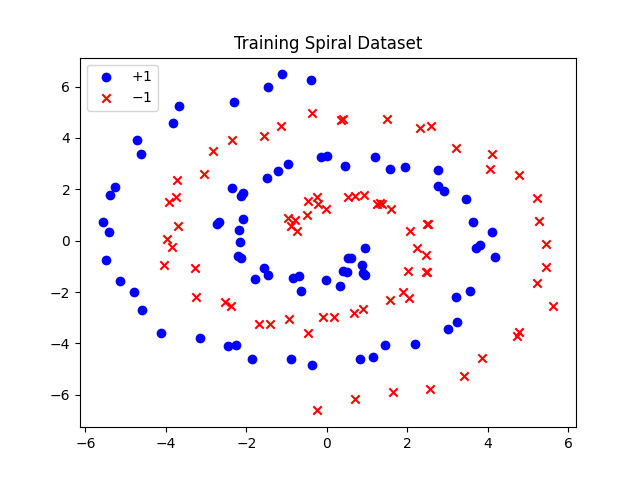

In [3]:
plt.figure()
plt.scatter(
    xTrSpiral[yTrSpiral == 1, 0],  # x-coordinate
    xTrSpiral[yTrSpiral == 1, 1],  # y-coordinate
    label="$+1$",
    c="blue",
    marker="o",
)
plt.scatter(
    xTrSpiral[yTrSpiral == -1, 0],  # x-coordinate
    xTrSpiral[yTrSpiral == -1, 1],  # y-coordinate
    label="$-1$",
    c="red",
    marker="x",
)
plt.title("Training Spiral Dataset")
plt.legend(loc="upper left")
plt.show()

The following code loads the ION dataset.

In [4]:
# Load some binary test data (labels are -1 and +1)
data = loadmat("ion.mat")

# Load the training data
xTrIon = data["xTr"].T
yTrIon = data["yTr"].flatten()

# Load the test data
xTeIon = data["xTe"].T
yTeIon = data["yTe"].flatten()

print(f"Number of test points in the ION dataset: {xTeIon.shape[0]}")
print(f"Number of training points in ION dataset: {xTrIon.shape[0]}")
print(f"Number of features in the ION dataset:    {xTrIon.shape[1]}")
print(f"Shape of the ION training data matrix:    {xTrIon.shape}")

print()
print("The ION training data matrix looks like this:")
print()

TrIon_for_display = np.concatenate([yTrIon[:, None], xTrIon], axis=1)
TrIon_for_display = TrIon_for_display[TrIon_for_display[:, 0].argsort()]

display(
    pd.DataFrame(
        data=TrIon_for_display,
        columns=["$y$"]
        + [rf"$[\mathbf{{x}}]_{ {i+1} }$" for i in range(xTrIon.shape[1])],
    ).round(2)
)

Number of test points in the ION dataset: 70
Number of training points in ION dataset: 281
Number of features in the ION dataset:    34
Shape of the ION training data matrix:    (281, 34)

The ION training data matrix looks like this:



,$y$,$[\mathbf{x}]_{1}$,$[\mathbf{x}]_{2}$,$[\mathbf{x}]_{3}$,$[\mathbf{x}]_{4}$,$[\mathbf{x}]_{5}$,$[\mathbf{x}]_{6}$,$[\mathbf{x}]_{7}$,$[\mathbf{x}]_{8}$,$[\mathbf{x}]_{9}$,...,$[\mathbf{x}]_{25}$,$[\mathbf{x}]_{26}$,$[\mathbf{x}]_{27}$,$[\mathbf{x}]_{28}$,$[\mathbf{x}]_{29}$,$[\mathbf{x}]_{30}$,$[\mathbf{x}]_{31}$,$[\mathbf{x}]_{32}$,$[\mathbf{x}]_{33}$,$[\mathbf{x}]_{34}$
0,-1.0,0.55,1.66,-0.56,1.01,1.83,-0.46,1.91,-1.48,-1.15,...,-0.51,-0.46,0.58,0.30,0.19,-0.30,-0.48,-0.45,-0.09,-0.0
1,-1.0,0.23,-0.04,1.61,-0.09,-0.23,-1.59,1.35,0.34,-0.03,...,0.36,-0.24,0.06,-0.21,-0.21,-0.04,0.00,0.22,0.08,-0.0
2,-1.0,2.18,-1.05,0.27,2.20,2.15,-2.48,-0.13,1.76,0.14,...,0.02,0.27,0.08,0.15,-0.22,0.09,-0.34,-0.45,-0.15,-0.0
3,-1.0,-2.10,1.56,0.55,-1.53,-0.92,-0.31,2.06,-0.30,-0.15,...,-0.53,0.30,-0.74,0.03,-0.14,0.23,0.00,-0.18,-0.02,0.0
4,-1.0,1.55,0.18,0.74,0.78,0.18,0.38,-0.10,-0.21,-0.63,...,0.01,0.19,-0.18,-0.18,0.02,-0.04,-0.22,0.19,0.05,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,1.0,3.37,-1.57,-1.80,-2.17,0.13,0.04,0.32,0.10,-0.40,...,0.29,0.14,0.06,-0.47,0.30,0.07,-0.54,0.27,-0.12,0.0
277,1.0,-0.05,0.03,0.39,0.11,-0.05,0.09,-0.10,0.17,0.16,...,-0.09,-0.06,0.07,-0.15,-0.04,-0.09,0.12,-0.15,-0.09,-0.0
278,1.0,-1.34,-0.13,-0.36,0.46,1.19,0.07,0.34,-0.38,0.23,...,-0.24,0.07,0.18,0.06,0.00,-0.66,0.11,0.19,0.13,-0.0
279,1.0,-1.24,0.13,-0.09,-0.27,0.06,-0.03,-0.32,0.09,0.17,...,0.09,-0.06,-0.02,0.07,0.04,-0.01,-0.03,-0.05,-0.04,-0.0


## Part One: Implement `sqimpurity` [Graded]

First, implement the function **`sqimpurity`**, which takes as input a vector of $n$ labels $y_i$ stored in the variable `yTr` and outputs the corresponding squared loss impurity:

$$
\sum_{i = 1}^{n} \left( y_i - \overline{y} \right)^2 \quad\textrm{, where}\quad \overline{y} = \frac{1}{n}\sum_{i=1}^{n} y_i
$$

Again, the squared loss impurity works fine even though our final objective is classification. This is because the labels are binary and classification problems can be framed as regression problems.

In [ ]:
def sqimpurity(yTr):
    """
    Computes the squared loss impurity (variance) of the labels.
    
    This function measures how "mixed" or "impure" the class labels are in a node.
    Lower impurity indicates more homogeneous labels (all similar), while higher impurity
    indicates more diverse labels (mix of different classes).

    Input:
        yTr: n-dimensional vector of labels

    Output:
        impurity: Weighted variance/squared loss impurity of the labels
        
    The mathematical formula is: Σ(y_i - ȳ)²
    where ȳ is the mean of all labels and we sum over all n labels.
    """
    (N,) = yTr.shape
    assert N > 0     # Must have at least one sample
    impurity = None  # Initialize variable to be returned

    # Calculate the mean (average) of all labels
    # This represents the "center" of the label distribution
    mean_y = np.mean(yTr)

    # Compute squared loss impurity: sum of squared deviations from the mean
    # Each (yTr - mean_y) is how far each label is from the average
    # We square these differences to penalize larger deviations
    # Finally, we sum all these squared deviations
    impurity = np.sum((yTr - mean_y) ** 2) # impurity will be 0 if labels are all the same (perfectly homogeneous)
    
    return impurity

Run the next cell to check your implementation of `sqimpurity`.

In [6]:
def sqimpurity_test1():
    """
    Check that impurity is a scalar
    """
    yTr = np.random.randn(100)  # Generate random training labels
    impurity = sqimpurity(yTr)  # Compute impurity
    return np.isscalar(impurity)


def sqimpurity_test2():
    """
    Check that impurity is non-negative
    """
    yTr = np.random.randn(100)  # Generate random training labels
    impurity = sqimpurity(yTr)  # Compute impurity
    return impurity >= 0


def sqimpurity_test3():
    """
    Check that impurity is close to zero when labels are homogeneous
    """
    yTr = np.ones(100)          # Generate an all-one vector as labels
    impurity = sqimpurity(yTr)  # Compute impurity
    return np.isclose(impurity, 0)


def sqimpurity_test4():
    """
    Check that impurity is sum of squares when data has mean of zero
    """
    yTr = np.arange(-5, 6)      # Generate a vector with mean zero
    impurity = sqimpurity(yTr)  # Compute impurity
    sum_of_squares = np.sum(yTr**2)
    return np.isclose(impurity, sum_of_squares)


def sqimpurity_test5():
    """
    Check that your impurity is close to our impurity
    """
    np.random.seed(1)           # Set random seed for consistency
    yTr = np.random.randn(100)  # Generate random training labels
    your_impurity = sqimpurity(yTr)
    our_impurity = sqimpurity_grader(yTr)
    return np.isclose(your_impurity, our_impurity)


runtest(sqimpurity_test1, "sqimpurity_test1")
runtest(sqimpurity_test2, "sqimpurity_test2")
runtest(sqimpurity_test3, "sqimpurity_test3")
runtest(sqimpurity_test4, "sqimpurity_test4")
runtest(sqimpurity_test5, "sqimpurity_test5")

Running Test: sqimpurity_test1 ... -0.03921158306970956
✔ Passed!
Running Test: sqimpurity_test2 ... 0.0665577384351999
✔ Passed!
Running Test: sqimpurity_test3 ... 1.0
✔ Passed!
Running Test: sqimpurity_test4 ... 0.0
✔ Passed!
Running Test: sqimpurity_test5 ... 0.060582852075698704
✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (sqimpurity_test1)

In [ ]:
# Auto-graded test cell worth one point (sqimpurity_test2)

In [ ]:
# Auto-graded test cell worth one point (sqimpurity_test3)

In [ ]:
# Auto-graded test cell worth one point (sqimpurity_test4)

In [ ]:
# Auto-graded test cell worth one point (sqimpurity_test5)

Let's plot the shape of the impurity function. We vary the mixture of labels in a set of $n$ labels and calculate the impurity of the labels. When the labels are mostly the same, the impurity should be low. When the labels are evenly split between $+1$ and $-1$, the impurity should be the highest.

1.0
0.8
0.6
0.4
0.2
0.0
-0.2
-0.4
-0.6
-0.8
-1.0


,fraction_pos,impurity
0,"[0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",0.0
1,"[0.0, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",3.6
2,"[0.0, 0.0, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",6.4
3,"[0.0, 0.0, 0.0, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, ...",8.4
4,"[0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 0.1, 0.1, 0.1, ...",9.6
5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 0.1, 0.1, ...",10.0
6,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 0.1, ...",9.6
7,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, ...",8.4
8,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",6.4
9,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3.6


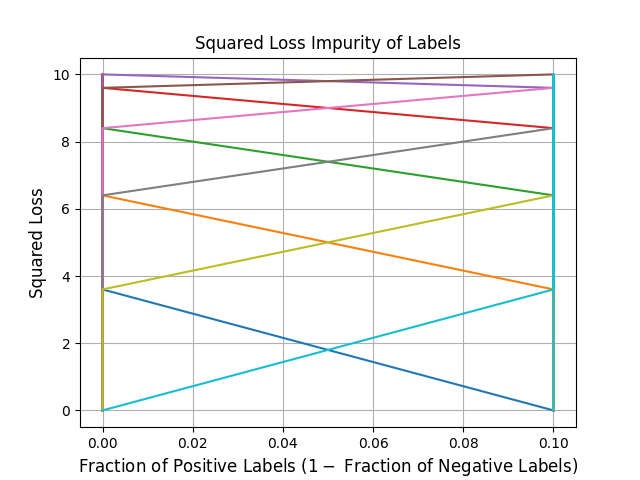

In [7]:
size = 10
y = np.ones(size)
fraction_pos, impurities = [], []

for i in range(size):
    fraction_pos.append(sum([y == 1]) / size)
    impurities.append(sqimpurity(y))
    y[i] = -1

fraction_pos.append(sum([y == 1]) / size)
impurities.append(sqimpurity(y))

display(pd.DataFrame(data={"fraction_pos": fraction_pos, "impurity": impurities}))

plt.figure()
plt.plot(fraction_pos, impurities)
plt.title("Squared Loss Impurity of Labels")
plt.xlabel("Fraction of Positive Labels ($1 -$ Fraction of Negative Labels)", fontsize=12)
plt.ylabel("Squared Loss", fontsize=12)
plt.grid()
plt.show()

## Part Two: Implement `sqsplit` [Graded]

Now implement **`sqsplit`**, which takes as input a data set of size $n \times d$ with labels and computes the best feature and the threshold/cut of the optimal split based on the squared loss impurity. The function outputs a feature dimension `0 <= feature < d`, a cut threshold `cut`, and the impurity loss `bestloss` of this best split.

Recall in the CART algorithm that, to find the split with the minimum impurity, you iterate over all features and cut values along each feature. We enforce that the cut value be the average of the two consecutive data points' feature values.

You should calculate the impurity of a node of data $S$ with two branches $S_L$ and $S_R$ as:

$$
\begin{aligned}
I(S) &= \frac{\left| S_L \right|}{|S|} I \left( S_L \right) + \frac{\left| S_R \right|}{|S|} I \left( S_R \right)\\[5pt]
&= \frac{1}{|S|}\sum_{(\mathbf{x}, y) \in S_L} \left( y-\overline{y}_{S_L} \right)^2 + \frac{1}{|S|} \sum_{(\mathbf{x}, y) \in S_R} \left( y - \overline{y}_{S_R} \right)^2\\[5pt]
&\propto \sum_{(\mathbf{x}, y) \in S_L} \left( y-\overline{y}_{S_L} \right)^2 + \sum_{(\mathbf{x}, y) \in S_R} \left( y - \overline{y}_{S_R} \right)^2
\end{aligned}
$$

**Implementation Notes:**

- For calculating the impurity of a node, you should just return the sum of left and right impurities instead of the average

- Returned `feature` must be 0-indexed to be consistent with programming in Python

- If two data points have the same value for a feature, avoid splitting between them and move to the next pair of data points

For example, consider the following `xTr` of size $4 \times 3$ and `yTr` for 4 labels:

$$
\begin{bmatrix}
1 & 0 & 2\\
2 & 0 & 1\\
0 & 0 & 1\\
2 & 1 & 2
\end{bmatrix}
\quad\text{and}\quad
\begin{bmatrix}
1\\1\\1\\-1
\end{bmatrix}
$$

Among possible features `[0, 1, 2]`, the best split would be at `feature = 1` and `cut = (0 + 1) / 2 = 0.5`.

---

If you're stuck, we recommend that you start with the naïve algorithm for finding the best split, which involves a double loop over all features `0 <= f < d` and all cut values (with `xTr` sorted along feature `f`)

```Python
xTr[0, f] < (xTr[i, f] + xTr[i+1, f]) / 2 < xTr[n-1, f]
```

This algorithm thus calculates impurities for `d(n-1)` splits. Here's the pseudocode:

<center>
    <img src="cart-id3_best_split_pseudocode.png" width="900px" />
</center>

In [ ]:
def sqsplit(xTr, yTr):
    """
    Finds the best feature, cut value, and impurity for a split of (xTr, yTr) based on squared loss impurity.
    
    This function is the core of the CART algorithm. It searches through all possible ways to split
    the data and finds the split that minimizes impurity (the most "pure" or homogeneous split).
    
    The algorithm:
    1. For each feature (column) in the data
    2. For each pair of consecutive values in that feature
    3. Try using the midpoint between them as a split threshold
    4. Calculate the impurity if we were to split at that point
    5. Keep track of the split that produces the lowest impurity

    Input:
        xTr: n x d matrix of data points (n samples, d features)
        yTr: n-dimensional vector of labels

    Output:
        feature:  index of the best cut's feature (0-indexed, ranges from 0 to d-1)
        cut:      cut-value (threshold) of the best split
        bestloss: squared loss impurity of the best split (lower is better)
    """
    n, d = xTr.shape
    assert d > 0  # Must have at least one dimension (feature)
    assert n > 1  # Must have at least two samples to split

    # Initialize with infinity so any real split will be better
    bestloss = np.inf
    feature = np.inf
    cut = np.inf

    for f in range(d):
        #TODO
        idif = np.where(np.logical_not(np.isclose(np.diff(xs, axis=0),0)))[0]
        if j in idif:
            left_loss = sqimpurity(ys[:j + 1])
            right_loss = sqimpurity(ys[j + 1:])
            total_loss = left_loss + right_loss

    # another example
    # # MAIN LOOP: Try each feature
    # for f in range(d):
    #     # Step 1: Sort all data points by the current feature
    #     # argsort returns the indices that would sort the array
    #     order = np.argsort(xTr[:, f])
        
    #     # Reorder both features and labels based on the sorted feature
    #     x_sorted = xTr[order, f]
    #     y_sorted = yTr[order]

    #     # Step 2: Initialize counters for left and right subsets
    #     # n_left/n_right: number of samples on each side
    #     # s_left/s_right: sum of labels on each side (for calculating mean)
    #     # q_left/q_right: sum of squared labels on each side (for efficient impurity calculation)
    #     n_left = 0
    #     s_left = 0.0
    #     q_left = 0.0

    #     n_right = len(y_sorted)
    #     s_right = np.sum(y_sorted)
    #     q_right = np.sum(y_sorted ** 2)

    #     # Step 3: Try each consecutive pair of points as a potential split
    #     for i in range(n - 1):
    #         # Get the current label being moved from right to left
    #         yi = y_sorted[i]

    #         # Move the point from right subset to left subset
    #         n_left += 1
    #         s_left += yi
    #         q_left += yi ** 2

    #         # Remove the point from the right subset
    #         n_right -= 1
    #         s_right -= yi
    #         q_right -= yi ** 2

    #         # Skip if two consecutive points have the same value in this feature
    #         # We can't split between identical values (they'd go to the same child)
    #         if x_sorted[i] == x_sorted[i + 1]:
    #             continue

    #         # Step 4: Calculate impurity for this potential split
    #         # Formula: impurity = Σ(y - mean_left)² + Σ(y - mean_right)²
    #         # Efficiently computed as: Σ(y²) - (Σy)²/n for each subset
    #         left_loss = q_left - (s_left * s_left) / n_left
    #         right_loss = q_right - (s_right * s_right) / n_right
    #         total_loss = left_loss + right_loss

    #         # The cut value is the midpoint between the two consecutive feature values
    #         # This ensures we split "between" the points rather than at exact values
    #         threshold = (x_sorted[i] + x_sorted[i + 1]) / 2.0

    #         # Step 5: Update best split if this one is better (lower impurity)
    #         if total_loss < bestloss:
    #             bestloss = total_loss
    #             feature = f
    #             cut = threshold
    
    return feature, cut, bestloss

Run the next cell to check that your function `sqsplit` function returns the correct values for several different input datasets.

In [9]:
t0 = time.time()
fid, cut, loss = sqsplit(xTrIon, yTrIon)
t1 = time.time()

print(f"Elapsed time: {t1-t0:.2f} seconds")
print("The best split is on feature 2 on value 0.304.")
print("Your tree split on feature %i on value %.3f.\n" % (fid, cut))


def sqsplit_test1():
    a = np.isclose(sqsplit(xor4, yor4)[2] / len(yor4), 0.25)
    b = np.isclose(sqsplit(xor3, yor3)[2] / len(yor3), 0.25)
    c = np.isclose(sqsplit(xor2, yor2)[2] / len(yor2), 0.25)
    return a and b and c


def sqsplit_test2():
    x = np.array(range(1000)).reshape(-1, 1)
    y = np.hstack([np.ones(500), -1 * np.ones(500)]).T
    _, cut, _ = sqsplit(x, y)
    return cut <= 500 or cut >= 499


def sqsplit_test3():
    fid, cut, loss = sqsplit(xor5, yor5)
    # cut should be 0.5 but 0 is also accepted
    return fid == 0 and (cut >= 0 or cut <= 1) and np.isclose(loss / len(yor5), 2 / 3)


runtest(sqsplit_test1, "sqsplit_test1")
runtest(sqsplit_test2, "sqsplit_test2")
runtest(sqsplit_test3, "sqsplit_test3")

Elapsed time: 0.15 seconds
The best split is on feature 2 on value 0.304.
Your tree split on feature 2 on value 0.304.

Running Test: sqsplit_test1 ... ✔ Passed!
Running Test: sqsplit_test2 ... ✔ Passed!
Running Test: sqsplit_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (sqsplit_test1)

In [ ]:
# Auto-graded test cell worth one point (sqsplit_test2)

In [ ]:
# Auto-graded test cell worth one point (sqsplit_test3)

## Part Three: Implement `cart` [Graded]

In this section, you will implement the function **`cart`**, which returns a regression tree based on the minimum squared loss splitting rule. You should use the function `sqsplit` to make your splits.

**Implementation Notes:**

We've provided a tree structure in the form of `TreeNode` for you that can be used for both leaves and nodes. To represent the leaves, you would set all fields except `prediction` to `None`.

Non-leaf nodes will have non-`None` fields for all except `prediction`:

1. `left`: node describing left subtree

2. `right`: node describing right subtree

3. `feature`: index of feature to cut (0-indexed as returned by `sqsplit`)

4. `cut`: cutoff value $t$ (left is $\leq t$ and right is $> t$)

5. `prediction`: `None`

In [ ]:
class TreeNode:
    """
    Class for instantiating decision trees.
    
    A TreeNode represents either:
    1. An INTERNAL NODE (decision node): has children and contains split information
       - left: TreeNode for data points that go left (feature <= cut)
       - right: TreeNode for data points that go right (feature > cut)
       - feature: the feature index to split on (0-indexed)
       - cut: the threshold value for the split
       - prediction: None (internal nodes don't make predictions)
    
    2. A LEAF NODE: has no children and contains a prediction
       - left: None (no left child)
       - right: None (no right child)
       - feature: None (no split feature)
       - cut: None (no threshold)
       - prediction: the predicted value for this leaf
    
    This structure allows us to recursively traverse from root to leaves to classify new data.
    """

    def __init__(self, left, right, feature, cut, prediction):
        # Get the shape of the left, right, feature, cut tuple
        node_or_leaf_args = [left, right, feature, cut]
        
        # Check that either ALL these arguments are None (leaf node)
        # or NONE of them are None (internal node)
        # This ensures consistency: we can't have half-filled internal nodes
        all_args_none = all([arg == None for arg in node_or_leaf_args])
        no_args_none = all([arg != None for arg in node_or_leaf_args])

        # Validate the node structure
        assert all_args_none or no_args_none

        # If all arguments are None, this is a LEAF NODE
        # Leaf nodes MUST have a prediction value
        if all_args_none:
            assert prediction is not None
        
        # If no arguments are None, this is an INTERNAL NODE
        # Internal nodes should NOT have a prediction value (set to None)
        if no_args_none:
            assert prediction is None

        # Store the tree structure
        # For leaf nodes: left/right/feature/cut are None, prediction is stored
        # For internal nodes: left/right/feature/cut are set, prediction is None
        self.left = left
        self.right = right
        self.feature = feature
        self.cut = cut
        self.prediction = prediction

        # A leaf node:
        # left = None
        # right = None
        # feature = None
        # cut = None
        # prediction = some value (e.g., mean of labels in that leaf)

        # decision node:
        # left = left subtree (TreeNode)
        # right = right subtree (TreeNode)
        # feature = index of feature to split on
        # cut = threshold value for the split
        # prediction = None (internal nodes don't make predictions)

The next cell creates a tree that predicts everything as zero. In this case, it has no left or right children &mdash; it is a leaf node such that

- `left=None`

- `right=None`

- `feature=None`

- `cut=None`

- `prediction=0`

In [11]:
root = TreeNode(None, None, None, None, 0)

The next cell creates a tree with depth 2 (or a tree with one split) such that:

- `left_leaf` returns a prediction of `1` if an example falls under the left subtree

- `right_leaf` returns a prediction of `2` if an example falls under the right subtree

- `root2` splits at feature `0` and cut of `1` with a prediction of `None`

In [12]:
left_leaf = TreeNode(None, None, None, None, 1)
right_leaf = TreeNode(None, None, None, None, 2)
root2 = TreeNode(left_leaf, right_leaf, 0, 1, None)

Now implement the function `cart` using **recursion** (you call `cart` on the left and right subtrees inside the `cart` function). Recall the pseudocode for the CART algorithm.

**NOTE:** In this implementation, you will be using **`np.mean`** for `prediction` argument. To check that floating point values in `xTr` are the same or not, you can use `np.isclose(xTr, xTr[0])`, which returns a list of `True` and `False` based on how different the rows of `xTr` are from the vector `xTr[0]`.

<center>
    <img src="cart-id3_pseudocode.png" width="900px" />
</center>

In [ ]:
def cart(xTr, yTr):
    """
    Builds a CART (Classification and Regression Tree) using recursive splitting.
    
    This is a recursive function that builds the entire decision tree by:
    1. Checking if the data is already "pure" (same label or same feature values)
    2. If pure, create a leaf node with the average prediction
    3. If not pure, find the best split and recursively build left and right subtrees
    
    This recursive approach naturally creates a tree structure where each internal node
    represents a decision (split) and each leaf node represents a final prediction.

    Input:
        xTr: n x d matrix of data (n samples, d features)
        yTr: n-dimensional vector of labels

    Output:
        tree: root TreeNode of the decision tree
    """
    n, d = xTr.shape
    node = None  # Intialize variable to be returned

    # BASE CASE 1: All labels are identical (homogeneous labels)
    # Check if all label values are very close to the first label (within floating point tolerance)
    # If so, this is a pure leaf with no need to split further
    if np.all(np.isclose(yTr, yTr[0])):
        # Create a leaf node with prediction = mean of all labels (which are all identical)
        node = TreeNode(None, None, None, None, prediction=np.mean(yTr))
        return node
    
    # BASE CASE 2: All feature values are identical
    # Check if all data points are identical (no variation in features)
    # If all rows are the same, we cannot make a meaningful split
    if np.all(np.isclose(xTr, xTr[0])):
        # Create a leaf node with prediction = mean of labels
        # This is the best we can do when all inputs are identical
        node = TreeNode(None, None, None, None, prediction=np.mean(yTr))
        return node
    
    # RECURSIVE CASE: Data is not pure, so find the best split
    # Use sqsplit to find which feature to split on and where to split
    feature, threshold, loss = sqsplit(xTr, yTr)

    # Split the data into left and right subsets based on the threshold
    # Left: all points where the feature value is <= threshold
    # Right: all points where the feature value is > threshold
    left = xTr[:, feature] <= threshold
    right = xTr[:, feature] > threshold
    
    # RECURSIVE CALLS: Recursively build the left and right subtrees
    # This naturally creates the tree structure through recursion
    left_tree = cart(xTr[left], yTr[left])
    right_tree = cart(xTr[right], yTr[right])
    
    # Create an internal (non-leaf) node that stores the split information
    # This node will have two children and no prediction value
    node = TreeNode(left_tree, right_tree, feature, threshold, None)

    return node

Run the next cell to check that your implementation of `cart` returns the correct predicted values for a sample dataset.

In [27]:
def cart_test1():
    t = cart(xor4, yor4)
    return DFSxor(t)


def cart_test2():
    """
    Check that every label appears exactly once in the tree
    """
    y = np.random.rand(16)
    t = cart(xor4, y)
    yTe = DFSpreds(t)[:]
    y.sort()
    yTe.sort()
    return np.all(np.isclose(y, yTe))


def cart_test3():
    xRep = np.concatenate([xor2, xor2])
    yRep = np.concatenate([yor2, 1 - yor2])
    t = cart(xRep, yRep)
    return DFSxorUnsplittable(t)


def cart_test4():
    """
    Check child nodes, features, and predictioins
    """
    X = np.ones((5, 2))  # Create a dataset with identical examples
    y = np.ones(5)

    # On this dataset, your cart algorithm should return
    # a single leaf node with prediction equal to 1.
    tree = cart(X, y)

    # Check that the tree has no children
    children_check = (tree.left is None) and (tree.right is None)

    # Make sure tree does not cut any feature and at any value
    feature_check = (tree.feature is None) and (tree.cut is None)

    # Check tree's prediction
    prediction_check = np.isclose(tree.prediction, 1)
    
    return children_check and feature_check and prediction_check


def cart_test5():
    """
    Check whether you set tree.feature and tree.cut to something
    """
    X = np.arange(4).reshape(-1, 1)
    y = np.array([0, 0, 1, 1])
    tree = cart(X, y)  # Your cart algorithm should generate one split
    feature_check = tree.feature is not None
    cut_check = tree.cut is not None
    return feature_check and cut_check


runtest(cart_test1, "cart_test1")
runtest(cart_test2, "cart_test2")
runtest(cart_test3, "cart_test3")
runtest(cart_test4, "cart_test4")
runtest(cart_test5, "cart_test5")

Running Test: cart_test1 ... ✔ Passed!
Running Test: cart_test2 ... ✔ Passed!
Running Test: cart_test3 ... ✔ Passed!
Running Test: cart_test4 ... ✔ Passed!
Running Test: cart_test5 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (cart_test1)

In [ ]:
# Auto-graded test cell worth one point (cart_test2)

In [ ]:
# Auto-graded test cell worth one point (cart_test3)

In [ ]:
# Auto-graded test cell worth one point (cart_test4)

In [ ]:
# Auto-graded test cell worth one point (cart_test5)

## Part Four: Implement `evaltree` [Graded]

Implement the function **`evaltree`**, which evaluates a decision tree on a given test data set. You essentially need to traverse the tree until you end up in a leaf, where you return the `prediction` value of the leaf. Like the `cart` function, you can call `evaltree` on the left subtree and right subtree on testing points that fall in the corresponding subtrees.

Here's some inspiration:

1. If the `tree` is a leaf, i.e. the left and right subtrees are `None`, return `tree.prediction` for all `m` testing points.

2. If the `tree` is non-leaf, using `tree.feature` and `tree.cut` find testing points with the feature value less than/equal to the threshold and greater than. Now, you can call `evaltree` on `tree.left` and the left set of testing points to obtain the left set's predictions. Then obtain the predictions for the right set, and return all predictions.

In [ ]:
def evaltree(tree, xTe):
    """
    Evaluates testing points in xTe using the decision tree.
    
    This function traverses the decision tree from the root to a leaf for each test point.
    At each internal node, it routes the point left or right based on the feature value
    and threshold. When it reaches a leaf, it returns that leaf's prediction.
    
    This is a recursive function that mirrors the structure of the tree itself:
    - If we reach a leaf, return its prediction
    - If we're at an internal node, split the data and recursively evaluate each subset

    Input:
        tree: TreeNode decision tree (root node)
        xTe: m x d matrix of test data points (m samples, d features)

    Output:
        preds: m-dimensional vector of predictions (one prediction per test point)
    """
    m = xTe.shape[0]
    # Create an empty array to store predictions for all test points
    preds = np.empty(m)

    # BASE CASE: We've reached a leaf node
    # A leaf has no left and right children (both are None)
    if tree.left is None and tree.right is None:
        # All test points reach this leaf, so they all get the same prediction
        # Fill the entire prediction array with the leaf's prediction value
        preds[:] = tree.prediction
        return preds
    
    # RECURSIVE CASE: We're at an internal node with a split
    # Route each test point to the left or right based on the split criterion
    
    # Create a boolean mask for which test points go left
    # Left: feature value <= threshold
    left = xTe[:, tree.feature] <= tree.cut
    
    # Create a boolean mask for which test points go right
    # Right: feature value > threshold
    right = xTe[:, tree.feature] > tree.cut
    
    # Recursively evaluate left subset on the left subtree
    # This fills in predictions for all points where left[i] is True
    preds[left] = evaltree(tree.left, xTe[left])
    
    # Recursively evaluate right subset on the right subtree
    # This fills in predictions for all points where right[i] is True
    preds[right] = evaltree(tree.right, xTe[right])

    return preds

Run the next cell to check that your implementation of `evaltree` returns the correct predictions for two sample trees.

In [32]:
# Fit a tree on the ION training data
t0 = time.time()
root = cart(xTrIon, yTrIon)
t1 = time.time()

# Calculate training error and test error
tr_err = np.mean((evaltree(root, xTrIon) - yTrIon) ** 2)
te_err = np.mean((evaltree(root, xTeIon) - yTeIon) ** 2)

print(f"Elapsed time: {t1 - t0:.4f} seconds")
print(f"Training MSE: {tr_err:.4f}")
print(f"Test MSE:     {te_err:.4f}\n")


def evaltree_test1():
    """
    Check that shuffling and expanding the data doesn't affect the predictions
    """
    t = cart(xor4, yor4)
    xor4te = xor4 + (np.sign(xor4 - 0.5) * 0.1)
    inds = np.arange(16)
    np.random.shuffle(inds)
    preds = evaltree(t, xor4te[inds, :])
    truth = yor4[inds]
    return np.all(np.isclose(preds, truth))


def evaltree_test2():
    """
    Check that a custom tree evaluates correctly
    """
    a = TreeNode(None, None, None, None, 1)
    b = TreeNode(None, None, None, None, -1)
    c = TreeNode(None, None, None, None, 0)
    d = TreeNode(None, None, None, None, -1)
    e = TreeNode(None, None, None, None, -1)
    x = TreeNode(a, b, 0, 10, None)
    y = TreeNode(x, c, 0, 20, None)
    z = TreeNode(d, e, 0, 40, None)
    t = TreeNode(y, z, 0, 30, None)
    preds = evaltree(t, np.array([[45, 35, 25, 15, 5]]).T)
    truth = np.array([-1, -1, 0, -1, 1])
    return np.all(np.isclose(preds, truth))


runtest(evaltree_test1, "evaltree_test1")
runtest(evaltree_test2, "evaltree_test2")

Elapsed time: 0.8296 seconds
Training MSE: 0.0000
Test MSE:     0.6857

Running Test: evaltree_test1 ... ✔ Passed!
Running Test: evaltree_test2 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (evaltree_test1)

In [ ]:
# Auto-graded test cell worth one point (evaltree_test2)

## Training and Testing a Classification Tree on the ION Dataset

The following code create a classification tree on the ION dataset and then apply the learned tree to an unknown dataset. If you implement everything correctly, you should get a training RSME that is close to zero.

In [33]:
t0 = time.time()
root = cart(xTrIon, yTrIon)
t1 = time.time()

tr_err = np.mean((evaltree(root, xTrIon) - yTrIon) ** 2)
te_err = np.mean((evaltree(root, xTeIon) - yTeIon) ** 2)

print(f"Elapsed time: {t1 - t0:.4f} seconds")
print(f"Training MSE: {tr_err:.4f}")
print(f"Test MSE:     {te_err:.4f}")

Elapsed time: 0.6672 seconds
Training MSE: 0.0000
Test MSE:     0.6857


### Visualize Your Tree

The following code defines a function `visclassifier`, which plots the decision boundary of a classifier in two dimensions. Execute the following code to see what the decision boundary of your tree looks like on the ion data set.

Training Error: 0.00%
Test Error:     0.00%


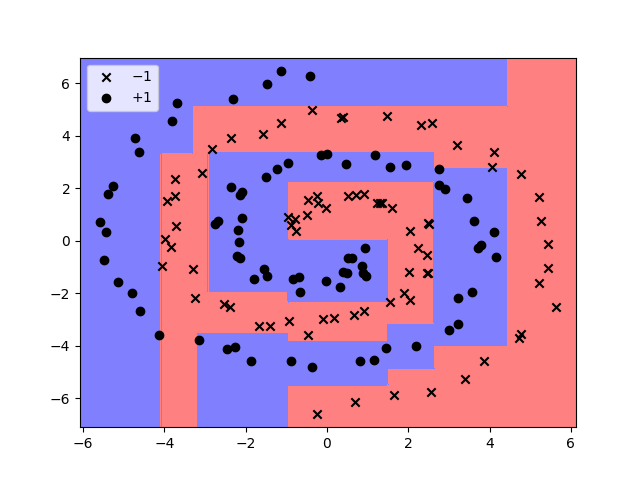

In [ ]:
def visclassifier(fun, xTr, yTr, w=None, b=0):
    """
    Visualize a classifier and its decision boundary.
    
    This function creates a 2D plot showing:
    1. The training data points colored by class
    2. The decision regions (background colors showing predicted class in each region)
    3. Optionally, a decision boundary line for linear classifiers
    
    The visualization works by creating a fine grid of points covering the entire plot area,
    evaluating the classifier on all grid points, and using contours to show prediction regions.

    Parameters:
        fun: A function that takes an m x d array of points and returns predictions
        xTr: n x d training data matrix
        yTr: n-dimensional vector of training labels
        w: Optional weight vector for linear classifiers (shows decision boundary)
        b: Optional bias term for linear classifiers
    """
    # Flatten the labels to ensure they're a 1D array
    yTr = np.array(yTr).flatten()

    # Find all unique class labels in the training set
    # This determines which colors/symbols to use for different classes
    classvals = np.unique(yTr)
    
    # Create a grid of points covering the feature space
    # We'll evaluate the classifier at each grid point to show decision regions
    
    # Return 300 evenly spaced numbers from (min - 0.5) to (max + 0.5)
    # This creates the x-axis range of our grid
    res = 300
    xrange = np.linspace(min(xTr[:, 0]) - 0.5, max(xTr[:, 0]) + 0.5, res)
    # Create the y-axis range of our grid
    yrange = np.linspace(min(xTr[:, 1]) - 0.5, max(xTr[:, 1]) + 0.5, res)

    # Create a 300x300 grid where each column contains the same x-values
    # This will be used as the x-coordinates for our grid points
    pixelX = repmat(xrange, res, 1)
    
    # Create a 300x300 grid where each row contains the same y-values
    # This will be used as the y-coordinates for our grid points
    pixelY = repmat(yrange, res, 1).T

    # Flatten the grids and combine them into an mx2 array of points to evaluate
    # Each row is one grid point with (x, y) coordinates
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    
    # Evaluate the classifier on all grid points
    # This gives us the predicted class for each location in the feature space
    testpreds = fun(xTe)

    # Reshape predictions back into a 300x300 grid matching our pixel grid
    # This allows us to visualize predictions as a heatmap
    Z = testpreds.reshape(res, res)
    Z[0,0] = 1  # Optional: scale the colors correctly

    plt.figure()

    # Define symbols and colors for visualization
    # Different symbols distinguish training points by class
    symbols = ["x", "o"]  # "x" for class -1, "o" for class +1
    labels = ["$-1$", "$+1$"]  # Text labels for legend
    # Background colors for prediction regions: red for -1, blue for +1
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]

    # Fill the background with contours showing the decision regions
    # np.sign(Z) converts predictions to -1 or +1
    plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

    # Plot the training data points
    # Create a scatter plot for each class with its own symbol and color
    for idx, c in enumerate(classvals):
        plt.scatter(
            xTr[yTr == c, 0],     # x-coordinates of training points in this class
            xTr[yTr == c, 1],     # y-coordinates of training points in this class
            label=labels[idx],    # Class label for legend (-1 or +1)
            marker=symbols[idx],  # Marker symbol (x or o)
            color="black",        # Training points are always black
        )

    # If a weight vector is provided, plot the decision boundary for a linear classifier
    if w is not None:
        w = np.array(w).flatten()
        # Scale factor to show the decision boundary appropriately
        alpha = -1 * b / (w**2).sum()
        # Draw an arrow showing the weight vector (direction of decision boundary)
        plt.quiver(w[0] * alpha, w[1] * alpha, w[0], w[1], linewidth=2, color=[0, 1, 0])

    # Set axis limits and labels
    plt.axis("tight")
    plt.legend(loc="upper left")
    # Display the plot
    plt.show()

### 2D Interactive Demo (Add Points With Clicks)

The following demo visualizes the CART classifier. Add your own points directly on the graph with click and `shift`+click to see the prediction boundaries. There will be a delay between clicks as the new classifier is trained.

Please keep in mind:
1. You must run (or rerun) this cell right before interacting with the plot.
2. Start the interactive demo by clicking the grid to add a positive point.
3. Click to add a positive point or shift+click to add a negative point.
4. You may notice a slight delay when adding points to the visualization.


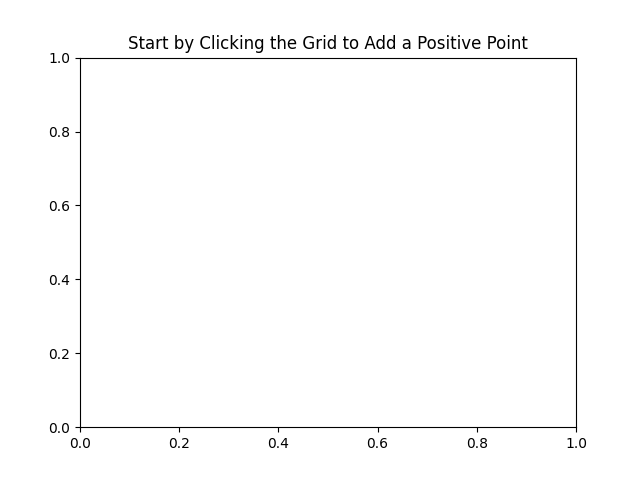

In [ ]:
def onclick_cart(event):
    """
    Interactive callback function triggered when user clicks on the plot.
    
    This function allows users to build a training dataset by clicking on the plot:
    - Regular click: adds a positive (+1) training point
    - Shift+click: adds a negative (-1) training point
    
    After adding each point:
    1. A new decision tree is trained on all accumulated points
    2. The decision regions are recomputed
    3. The plot is updated to show the new tree's decision boundary
    
    This interactive demo helps visualize how decision trees adapt as new data is added.
    """
    # Use the global keyword to modify variables outside this function
    global xTrain, yTrain

    # Determine the class label based on modifier key
    # If Shift is pressed, the point is negative (-1), otherwise positive (+1)
    if event.key == "shift":
        label = -1  # Shift+click: negative class
    else:
        label = 1   # Regular click: positive class

    # Extract the (x, y) coordinates where the user clicked
    # event.xdata and event.ydata are the plot coordinates of the click
    pos = np.array([[event.xdata, event.ydata]])

    # Add the new point to the global training data
    # Concatenate the new point with all previously added points
    xTrain = np.concatenate((xTrain, pos), axis=0)
    # Add the corresponding label to the global label array
    yTrain = np.append(yTrain, label)

    # Get all unique class labels that have been added so far
    classvals = np.unique(yTrain)
    
    # Create a fine grid to evaluate the tree's predictions across the entire plot area
    # This will show the decision regions learned by the tree
    
    # Create 300 evenly spaced x-values from 0 to 1
    res = 300
    xrange = np.linspace(0, 1, res)
    # Create 300 evenly spaced y-values from 0 to 1
    yrange = np.linspace(0, 1, res)

    # Create 300x300 grid of x-coordinates using matrix repetition
    pixelX = repmat(xrange, res, 1)
    # Create 300x300 grid of y-coordinates
    pixelY = repmat(yrange, res, 1).T

    # Train a new decision tree on all accumulated training points
    tree = cart(xTrain, np.array(yTrain).flatten())
    # Create a function that evaluates the tree (wraps evaltree)
    fun = lambda X: evaltree(tree, X)

    # Evaluate the tree on all grid points to determine prediction regions
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = fun(xTe)

    # Reshape predictions back to grid format for visualization
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Scale the color map correctly

    # Clear the current plot axes to redraw everything
    plt.cla()
    # Set x-axis limits
    plt.xlim((0, 1))
    # Set y-axis limits
    plt.ylim((0, 1))
    
    # Define labels and visual properties for the two classes
    labels = ["$-1$", "$+1$"]          # Class labels for legend
    symbols = ["x", "o"]               # "x" for -1, "o" for +1
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1, blue for +1

    # Handle special case: only positive points have been added
    # In this case, we don't show both decision regions (no -1 class to separate)
    if len(classvals) == 1 and 1 in classvals:
        # Fill entire background with blue (all predictions are +1)
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=[[0.5, 0.5, 1], [0.5, 0.5, 1]])
        
        # Plot training points with "o" markers (since only +1 class)
        for idx, c in enumerate(classvals):
            plt.scatter(
                xTrain[yTrain == c, 0],  # x-coordinates of +1 points
                xTrain[yTrain == c, 1],  # y-coordinates of +1 points
                label="$+1$",            # Label
                marker="o",              # Marker
                color="black",           # Training points in black
            )
    else:
        # Normal case: both classes are present
        # Fill background with color regions showing predictions for each class
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

        # Plot training data points with different markers for each class
        for idx, c in enumerate(classvals):
            plt.scatter(
                xTrain[yTrain == c, 0],  # x-coordinates of this class's points
                xTrain[yTrain == c, 1],  # y-coordinates of this class's points
                label=labels[idx],       # Class label (-1 or +1)
                marker=symbols[idx],     # Class marker (x or o)
                color="black",           # Training points in black
            )

    # Add a title and legend to the plot
    plt.title("Click: Positive Point, Shift+Click: Negative Point")
    plt.legend(loc="upper left")
    plt.show()

### Scikit-Learn

Scikit-learn also provides an implementation of [Regression Trees](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) (and [Decision Tree Classifiers](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)). The usage is pretty straightforward: 

- Define the regression tree with the impurity function (and other settings)

-  Fit to the training set

-  Evaluate on any dataset

In [36]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

t0 = time.time()
tree = DecisionTreeRegressor(
    criterion="squared_error",  # Impurity function = Mean Squared Error (squared loss)
    splitter="best",            # Take the best split
    max_depth=None,             # Expand the tree to the maximum depth possible
)
tree.fit(xTrSpiral, yTrSpiral)
t1 = time.time()

tr_err = np.mean((tree.predict(xTrSpiral) - yTrSpiral) ** 2)
te_err = np.mean((tree.predict(xTeSpiral) - yTeSpiral) ** 2)

print(f"Elapsed time: {t1 - t0:.4f} seconds")
print(f"Training MSE: {tr_err:.4f}")
print(f"Test MSE:     {te_err:.4f}")

Elapsed time: 0.0225 seconds
Training MSE: 0.0000
Test MSE:     0.0000


Scikit-learn also provides a tree plotting function, which is again quite simple to use. This is extremely useful while debugging a decision tree.

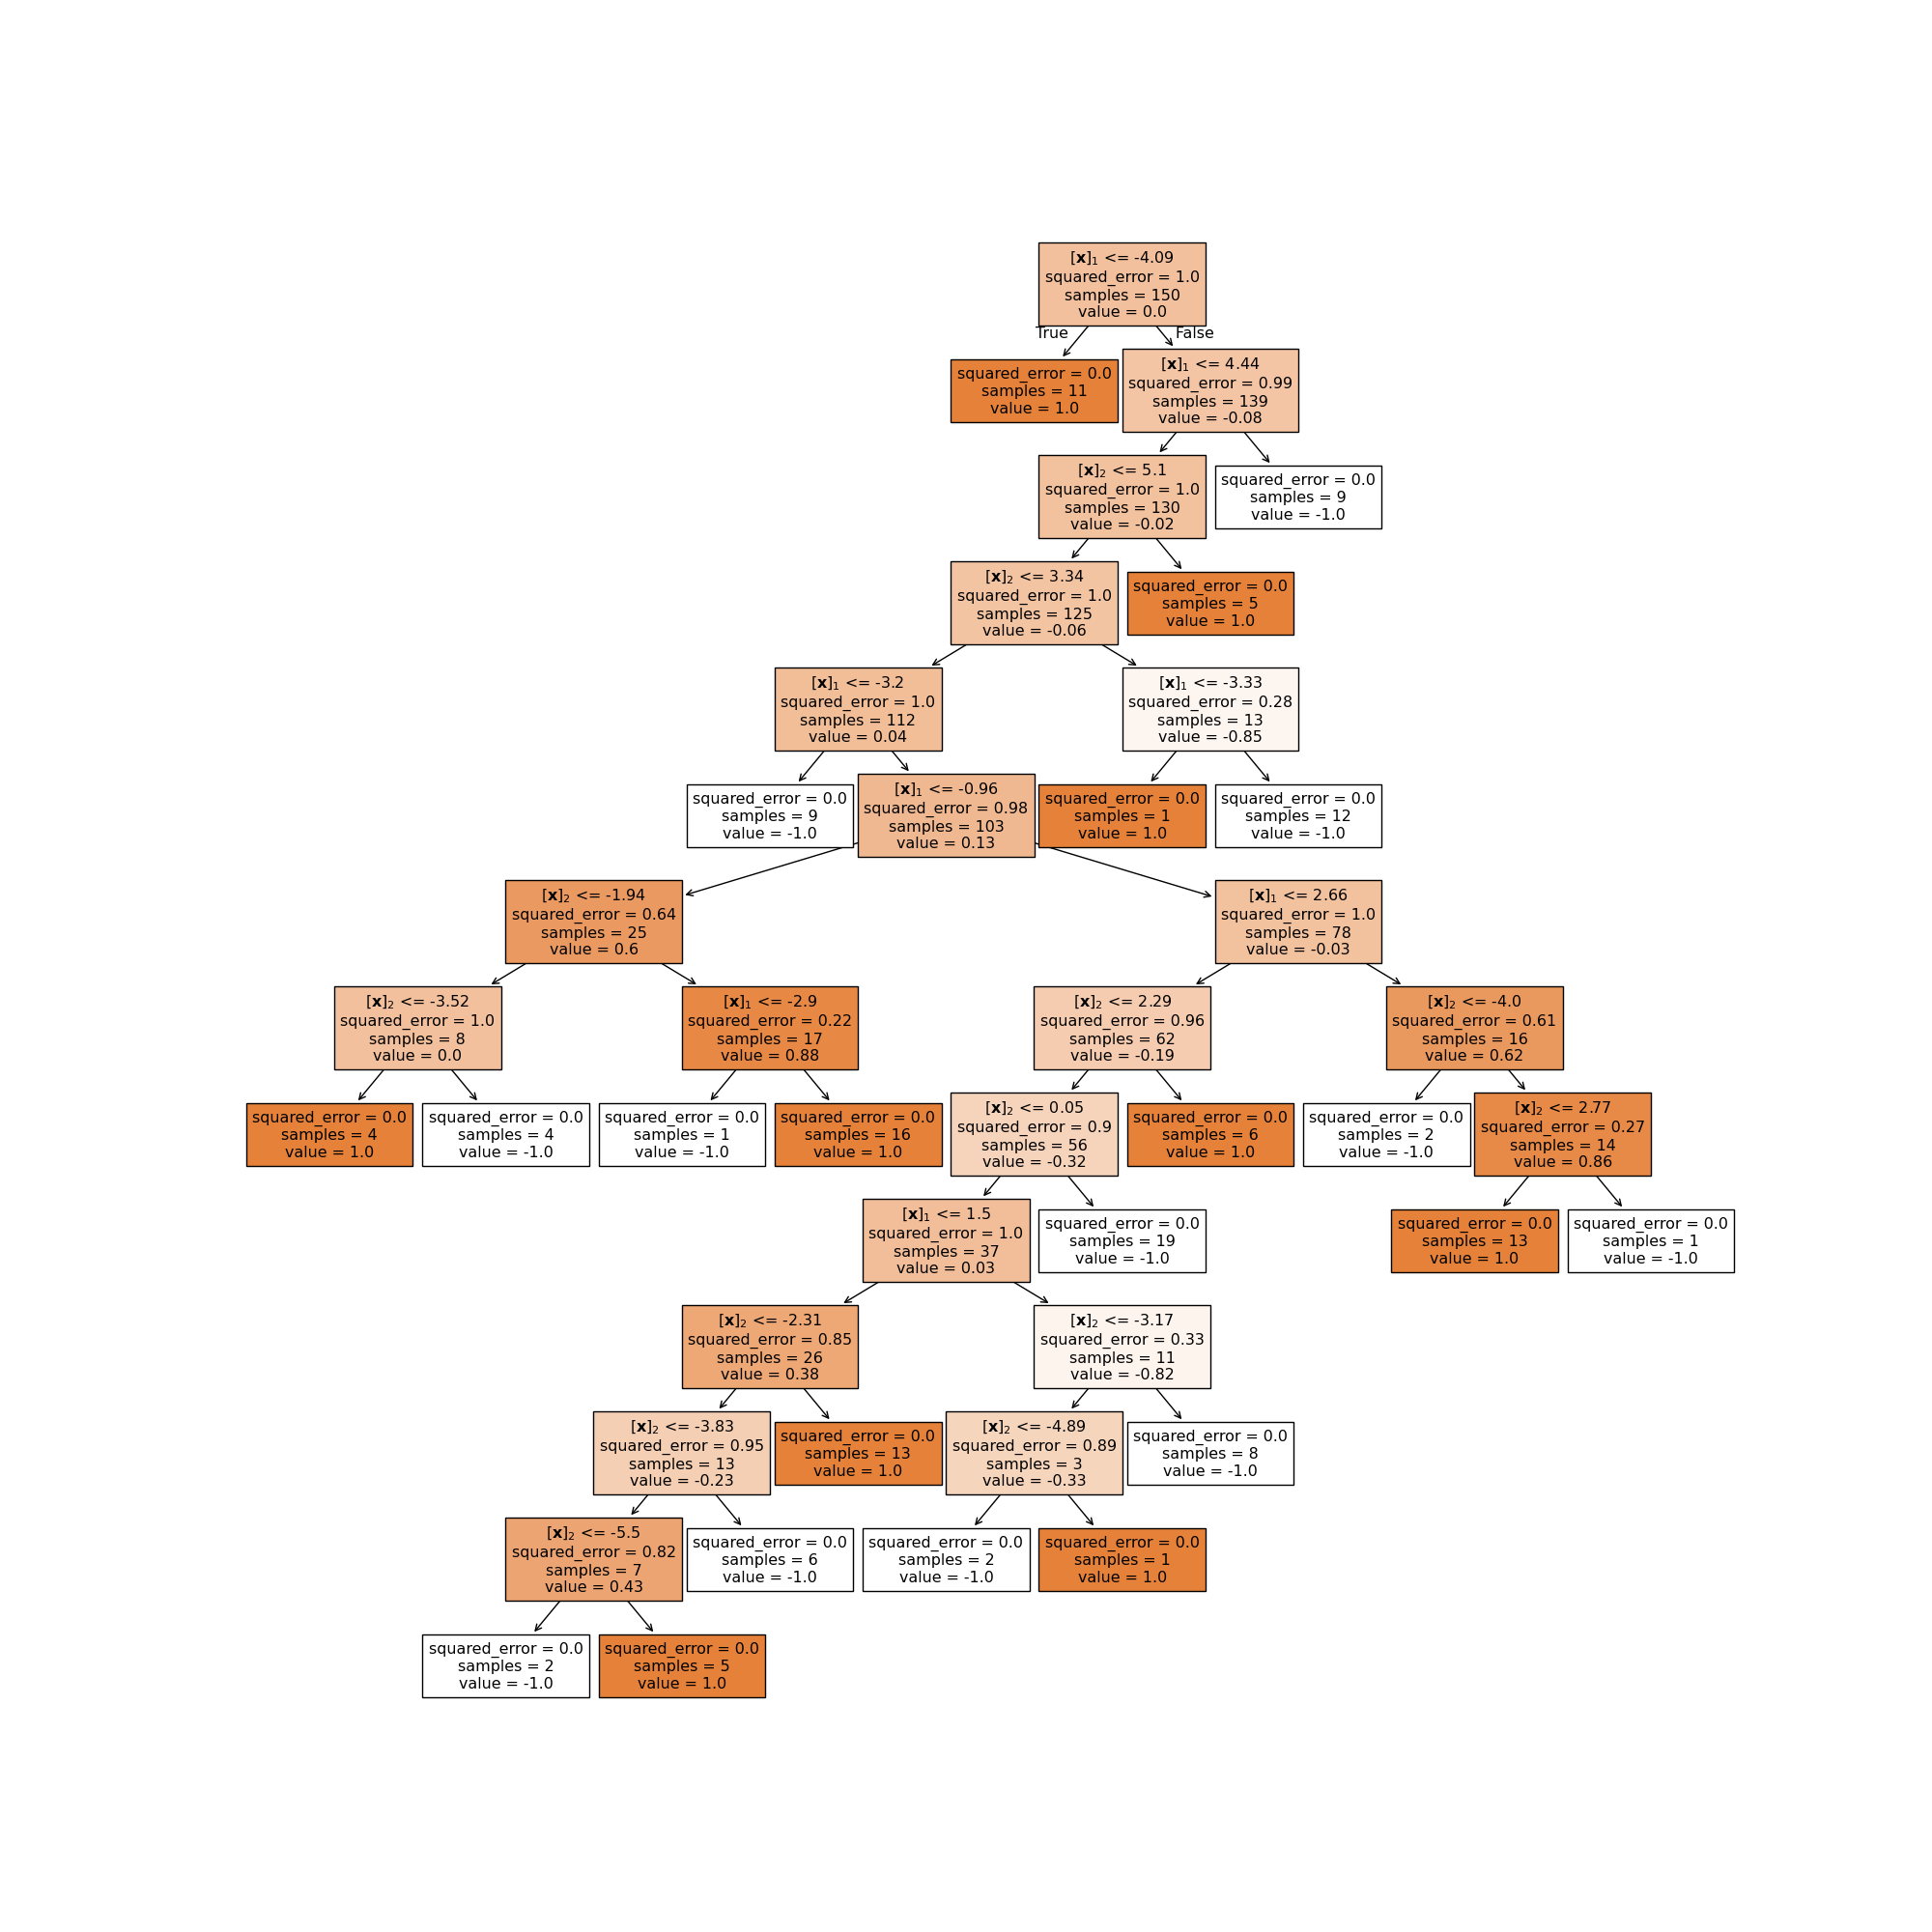

In [37]:
fig, ax = plt.subplots(figsize=(20, 20))
_ = plot_tree(
    tree,
    ax=ax,
    precision=2,
    feature_names=[rf"$[\mathbf{{x}}]_{i+1}$" for i in range(2)],
    filled=True,
)